# Entrenar YOLO nano para reconocer nuestros peluches

El flujo es: configurar entorno → revisar datos y etiquetas → entrenar → validar → evaluar test → predecir → guardar pesos.

**Antes de ejecutar:** en la terminal, desde la raíz del repo, ejecuta `uv sync` y selecciona `.venv/bin/python` como kernel de este notebook en VS Code.

Ejecuta las celdas en orden. El entrenamiento utiliza los pesos preentrenados `yolo26n.pt`, que se descargan la primera vez. El dataset contiene tres clases propias; no se garantiza conservar las categorías originales de COCO.


In [ ]:
from pathlib import Path
from collections import Counter
import hashlib
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from ultralytics import YOLO
import yaml


Python: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/bin/python
Ultralytics: 8.4.190
PyTorch: 2.14.1


## 1. Configurar rutas y entrenamiento

El notebook encuentra la raíz tanto si el kernel se inicia en el repo como en una subcarpeta. Selecciona CUDA si hay una GPU NVIDIA, MPS si PyTorch puede usar la GPU de Apple, o CPU como alternativa. Puedes cambiar `DEVICE` manualmente. CPU funciona, pero el entrenamiento tarda más.

Empieza con 50 épocas, imágenes de 640 píxeles y lotes de 4. `patience=10` permite detenerse si la validación deja de mejorar. Son parámetros iniciales, no una garantía de precisión.


In [2]:
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file()
     and (p / "Imagenes peluches" / "data.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Abre este notebook desde el repositorio y conserva Imagenes peluches/data.yaml.")

DATASET_DIR = ROOT / "Imagenes peluches"
OUTPUT_DIR = ROOT / "runs" / "peluches"
MODEL_WEIGHTS = "yolo26n.pt"
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 4
DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("Dataset:", DATASET_DIR)
print("Dispositivo:", DEVICE)
print("Resultados:", OUTPUT_DIR)


Dataset: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/Imagenes peluches
Dispositivo: mps
Resultados: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches


## 2. Preparar el archivo de configuración

El export de Roboflow contiene rutas `../train/images`, etc. Creamos un YAML local con rutas inequívocas, sin modificar el export original. Los IDs y nombres de clases se conservan tal como fueron etiquetados. Los aumentos de Roboflow ya están en `train`; validación y test se mantienen separados.


In [3]:
with (DATASET_DIR / "data.yaml").open() as f:
    exported_config = yaml.safe_load(f)

names = exported_config["names"]
CLASS_NAMES = names if isinstance(names, list) else [names[i] for i in range(len(names))]
assert exported_config.get("nc", len(CLASS_NAMES)) == len(CLASS_NAMES)

config = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_YAML = OUTPUT_DIR / "dataset.yaml"
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())


path: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/Imagenes peluches
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- peluche_Juan Jose
- peluche_martin
- peluche_sebastian



## 3. Comprobar imágenes y etiquetas

Verificamos que cada imagen se pueda leer, que tenga archivo de etiquetas y que cada caja use un ID válido y coordenadas normalizadas. Un archivo de etiquetas vacío es válido para una imagen negativa. Mostramos las cajas por clase para detectar clases con muy pocos ejemplos.

También comprobamos duplicados exactos entre grupos. Esto no detecta fotos casi iguales ni variantes aumentadas; esas deben revisarse por sesión de captura.


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
images_by_split = {}
errors = []
hashes = {}

for split in ("train", "valid", "test"):
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"
    if not image_dir.is_dir() or not label_dir.is_dir():
        errors.append(f"Faltan carpetas images/labels de {split}")
        continue
    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    images_by_split[split] = images
    if not images:
        errors.append(f"No hay imágenes en {split}")
    counts = Counter()
    for image_path in images:
        try:
            with Image.open(image_path) as im:
                im.verify()
        except Exception as exc:
            errors.append(f"Imagen inválida: {image_path.name}: {exc}")
        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        if digest in hashes and hashes[digest] != split:
            errors.append(f"Imagen duplicada entre {hashes[digest]} y {split}: {image_path.name}")
        hashes[digest] = split
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.is_file():
            errors.append(f"Falta etiqueta: {label_path}")
            continue
        for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
            if not line.strip():
                continue
            try:
                values = list(map(float, line.split()))
                assert len(values) == 5, "Se esperan clase, x, y, ancho y alto"
                cls, x, y, w, h = values
                assert cls.is_integer() and 0 <= cls < len(CLASS_NAMES), "Clase inválida"
                assert all(0 <= v <= 1 for v in (x, y, w, h)), "Coordenadas fuera de [0, 1]"
                assert w > 0 and h > 0, "Caja sin tamaño"
                counts[int(cls)] += 1
            except (ValueError, AssertionError) as exc:
                errors.append(f"{label_path.name}:{line_number}: {exc}")
    print(f"{split}: {len(images)} imágenes")
    for class_id, class_name in enumerate(CLASS_NAMES):
        print(f"  {class_name}: {counts[class_id]} cajas")
        if counts[class_id] == 0:
            errors.append(f"La clase {class_name} no aparece en {split}")

if errors:
    raise ValueError("Revisa el dataset:\n" + "\n".join(errors[:30]))
print("Dataset verificado.")


train: 308 imágenes
  peluche_Juan Jose: 80 cajas
  peluche_martin: 110 cajas
  peluche_sebastian: 84 cajas
valid: 44 imágenes
  peluche_Juan Jose: 9 cajas
  peluche_martin: 26 cajas
  peluche_sebastian: 4 cajas
test: 22 imágenes
  peluche_Juan Jose: 1 cajas
  peluche_martin: 14 cajas
  peluche_sebastian: 4 cajas
Dataset verificado.


## 4. Visualizar fotos con sus cajas

Comprueba que las cajas rodeen al peluche correcto y que los nombres coincidan. Para ver otras imágenes, cambia `PREVIEW_SEED`.


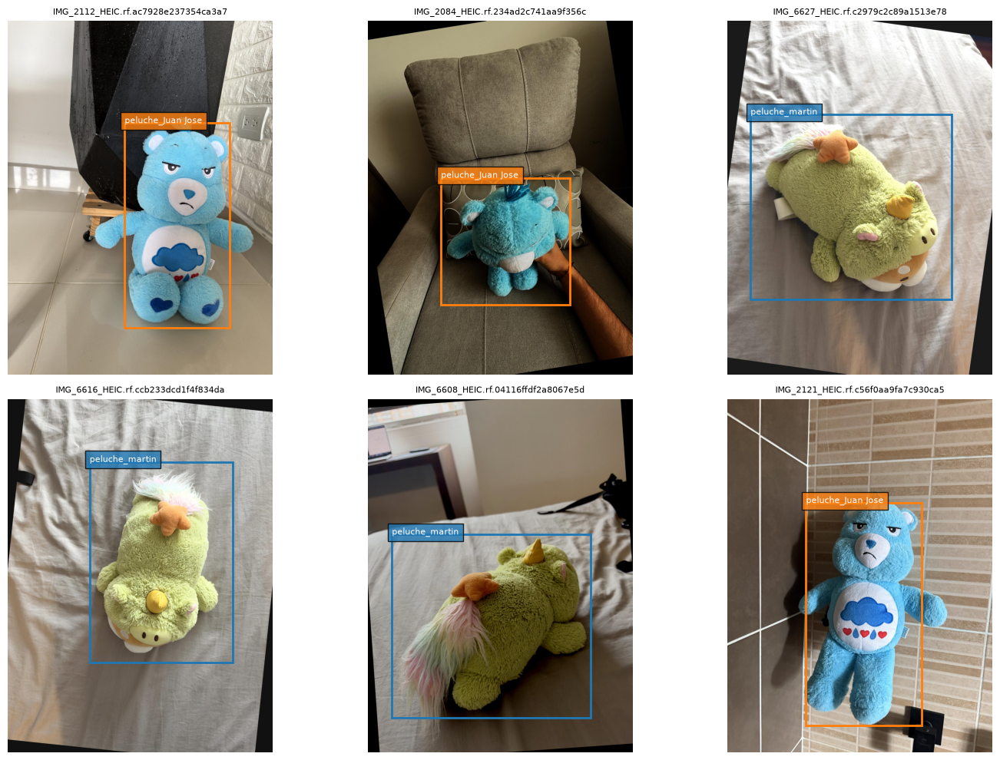

In [5]:
import random

PREVIEW_SEED = 42
sample = random.Random(PREVIEW_SEED).sample(
    images_by_split["train"], min(6, len(images_by_split["train"]))
)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
colors = ["tab:orange", "tab:blue", "tab:green"]
for ax, image_path in zip(axes.flat, sample):
    with Image.open(image_path) as source:
        image = source.convert("RGB")
    width, height = image.size
    ax.imshow(image)
    label_path = DATASET_DIR / "train" / "labels" / f"{image_path.stem}.txt"
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        cls, x, y, w, h = map(float, line.split())
        left, top = (x - w / 2) * width, (y - h / 2) * height
        color = colors[int(cls) % len(colors)]
        ax.add_patch(Rectangle((left, top), w * width, h * height,
                               fill=False, edgecolor=color, linewidth=2))
        ax.text(left, top, CLASS_NAMES[int(cls)], color="white",
                fontsize=8, bbox={"facecolor": color, "alpha": 0.8})
    ax.set_title(image_path.name[:35], fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Cargar YOLO nano y entrenar

Equivale al bloque `model.train(...)` del ejemplo BCCD. Ejecutar esta celda inicia el entrenamiento real. Cada ejecución crea su carpeta, sin sobrescribir las anteriores.

Ultralytics también aplica aumentos durante el entrenamiento. Usamos ajustes moderados porque el dataset ya fue aumentado en Roboflow. Si falta memoria, baja `BATCH_SIZE` a 2 o 1.

La primera ejecución requiere internet para descargar `yolo26n.pt`.


In [6]:
model = YOLO(MODEL_WEIGHTS)
model.info()


YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [7]:
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    patience=10,
    workers=0,
    seed=42,
    project=str(OUTPUT_DIR),
    name="nano",
    exist_ok=False,
    plots=True,
    val=True,
    degrees=0.0,
    fliplr=0.0,
    hsv_h=0.0,
    hsv_s=0.2,
    hsv_v=0.1,
    mosaic=0.0,
    translate=0.05,
    scale=0.1,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
print("Resultados:", RUN_DIR)
print("Mejores pesos:", BEST_WEIGHTS)


Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.2, hsv_v=0.1, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=nano, nbs=64, nms=None, opset=No

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      2.23G      1.142      42.55    0.02071          2        640: 100% ━━━━━━━━━━━━ 77/77 3.9it/s 19.9s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.2it/s 1.9s0.2ss
                   all         44         39      0.905      0.672      0.843       0.62

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      2.23G      1.051      11.26    0.01839          4        640: 100% ━━━━━━━━━━━━ 77/77 6.6it/s 11.7s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.9it/s 1.2s0.2s
                   all         44         39      0.945      0.906      0.966      0.714

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.29G      1.436       5.72    0.02354          4        640: 0% ──────────── 0/77  0.5s

...

      43/50      2.26G     0.3438     0.2033   0.005417          3        640: 100% ━━━━━━━━━━━━ 77/77 6.2it/s 12.4s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.9it/s 1.2s0.2s
                   all         44         39       0.98      0.967      0.995      0.773

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      44/50      2.25G     0.2701    0.09484   0.005698          4        640: 0% ──────────── 0/77  0.6s

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      44/50      2.24G     0.3216      0.168   0.004967          4        640: 100% ━━━━━━━━━━━━ 77/77 6.2it/s 12.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 5.4it/s 1.1s0.2s
                   all         44         39      0.978      0.967      0.995      0.774

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      45/50      2.21G     0.3206     0.2359   0.004203          4        640: 0% ──────────── 0/77  0.6s

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      45/50      2.23G     0.3161      0.205   0.004983          3        640: 100% ━━━━━━━━━━━━ 77/77 6.4it/s 12.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 5.3it/s 1.1s0.2s
                   all         44         39      0.981      0.963      0.991      0.777
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 35, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

45 epochs completed in 0.171 hours.
Optimizer stripped from /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/nano/weights/last.pt, 5.4MB
Optimizer stripped from /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/nano/weights/best.pt, 5.4MB

Validating /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/nano/weights/best.pt...
Ultralytics 8.4.190 🚀 P

## 6. Revisar curvas y ejemplos del entrenamiento

Las curvas y la validación ayudan a detectar sobreajuste. El rendimiento sobre imágenes nuevas es más importante que acertar todas las fotos de entrenamiento.


results.png


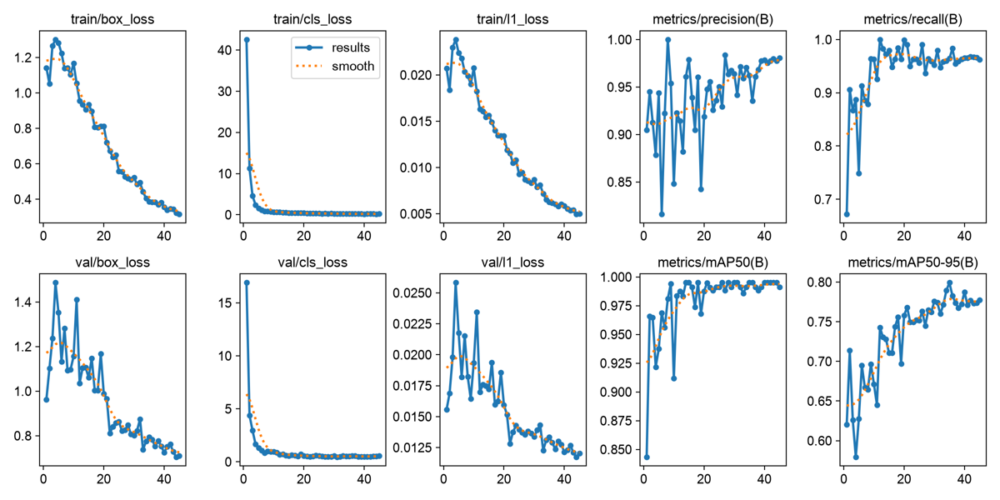

train_batch0.jpg


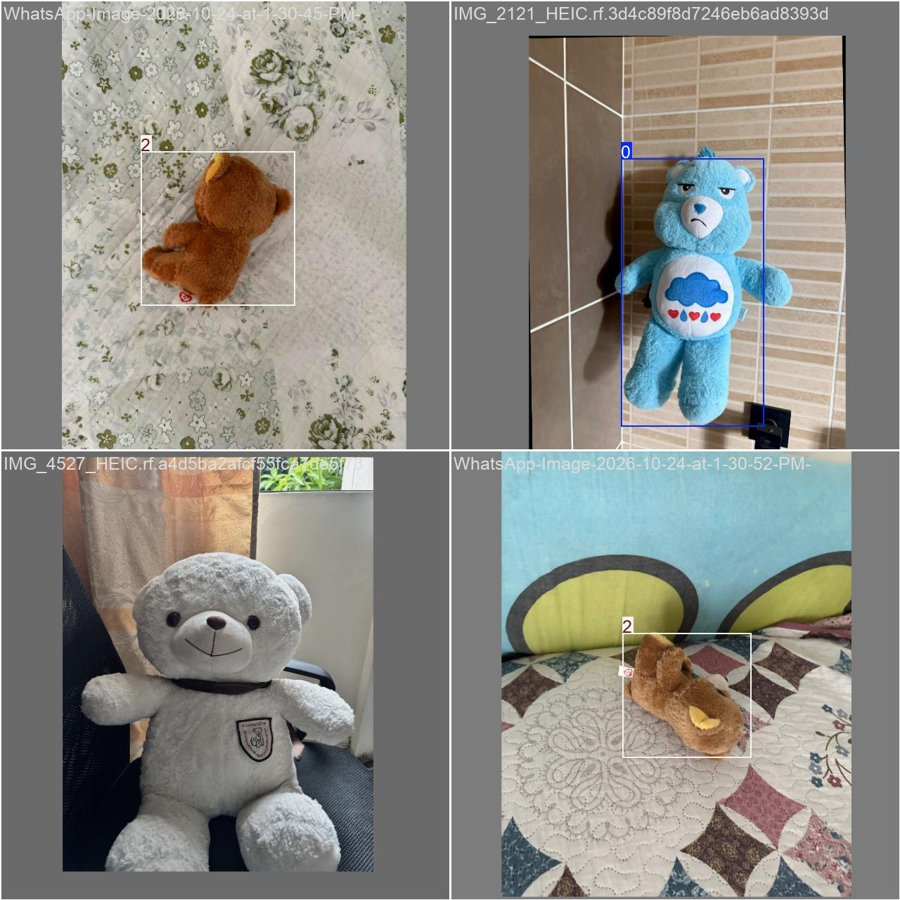

confusion_matrix.png


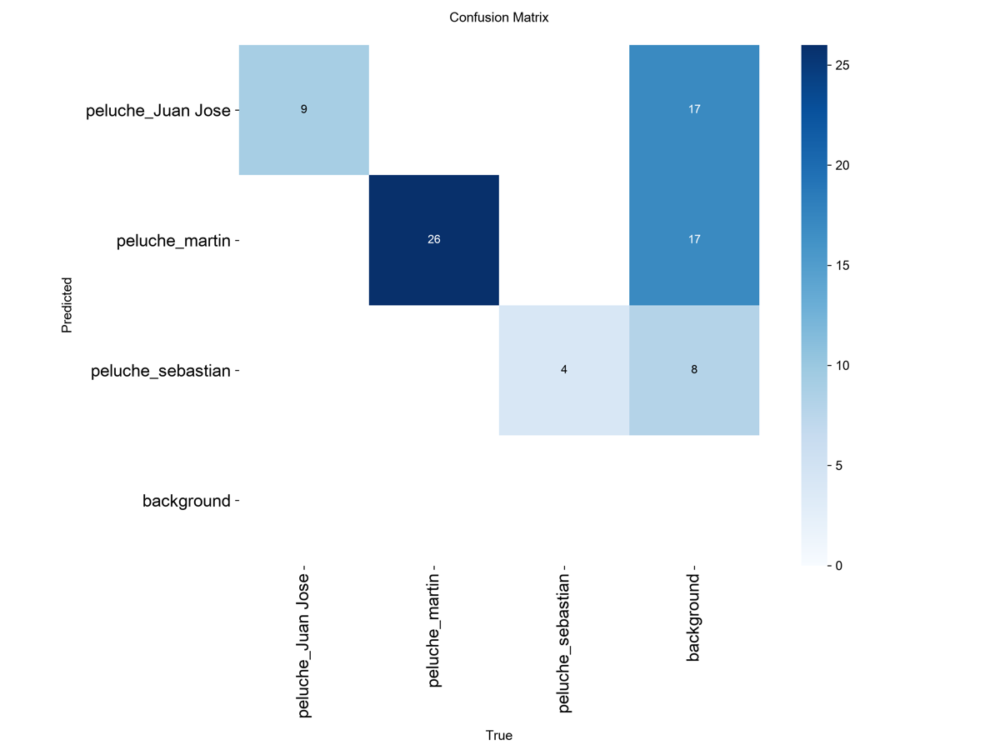

In [8]:
from IPython.display import display

for filename in ("results.png", "train_batch0.jpg", "confusion_matrix.png"):
    path = RUN_DIR / filename
    if path.is_file():
        print(filename)
        with Image.open(path) as image:
            preview = image.copy()
        preview.thumbnail((1200, 900))
        display(preview)


## 7. Evaluar los mejores pesos en validación

Usamos `best.pt`, no el último estado de entrenamiento. mAP50 y mAP50-95 van de 0 a 1; cuanto más alto, mejor. Revisa también precisión y recall por clase.


In [9]:
best_model = YOLO(str(BEST_WEIGHTS))
validation = best_model.val(
    data=str(DATA_YAML), split="val", device=DEVICE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, workers=0,
    project=str(OUTPUT_DIR), name="validacion", plots=True,
)
print(f"mAP50: {validation.box.map50:.3f}")
print(f"mAP50-95: {validation.box.map:.3f}")
for class_id, class_map in zip(validation.box.ap_class_index, validation.box.maps[validation.box.ap_class_index]):
    print(f"{CLASS_NAMES[int(class_id)]}: mAP50-95={class_map:.3f}")


Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4605.9±1445.1 MB/s, size: 336.5 KB)
val: Scanning /Users/martinrestrepocoral/Desktop/IA/yolo_nao/Imagenes peluches/valid/labels.cache... 44 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 36.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 11.5it/s 1.0s.1s
                   all         44         39      0.962      0.964      0.995      0.796
     peluche_Juan Jose          9          9          1      0.893      0.995      0.626
        peluche_martin         26         26      0.987          1      0.995      0.891
     peluche_sebastian          4          4        0.9          1      0.995      0.871
Speed: 0.3ms preprocess, 10.2ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to

## 8. Evaluación final con test

Ejecuta este bloque cuando hayas elegido la configuración con validación. No uses test para ajustar repetidamente los parámetros: dejaría de ser una evaluación independiente. Con 22 fotos de prueba, las métricas todavía pueden variar bastante.


In [10]:
test_metrics = best_model.val(
    data=str(DATA_YAML), split="test", device=DEVICE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, workers=0,
    project=str(OUTPUT_DIR), name="test", plots=True,
)
print(f"Test mAP50: {test_metrics.box.map50:.3f}")
print(f"Test mAP50-95: {test_metrics.box.map:.3f}")


Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1006.3±875.4 MB/s, size: 328.3 KB)
val: Scanning /Users/martinrestrepocoral/Desktop/IA/yolo_nao/Imagenes peluches/test/labels... 22 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 5.3Kit/s 0.0s
val: New cache created: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/Imagenes peluches/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 12.8it/s 0.5s.2s
                   all         22         19      0.955          1      0.995      0.746
     peluche_Juan Jose          1          1      0.971          1      0.995      0.497
        peluche_martin         14         14      0.996          1      0.995      0.881
     peluche_sebastian          4          4      0.897          1      0.995      0.858
Spe

## 9. Predecir imágenes

Este ejemplo muestra algunas fotos de test. Después cambia `SOURCE` por una imagen, una carpeta de fotos nuevas o un video. Prueba también fotos con otros peluches y con los tres objetivos juntos. `conf=0.25` es un umbral inicial.



0: 640x480 1 peluche_Juan Jose, 0.7ms
1: 640x480 (no detections), 0.7ms
2: 640x480 (no detections), 0.7ms
3: 640x480 (no detections), 0.7ms
4: 640x480 1 peluche_martin, 0.7ms
5: 640x480 1 peluche_martin, 0.7ms
Speed: 13.0ms preprocess, 0.7ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/predicciones


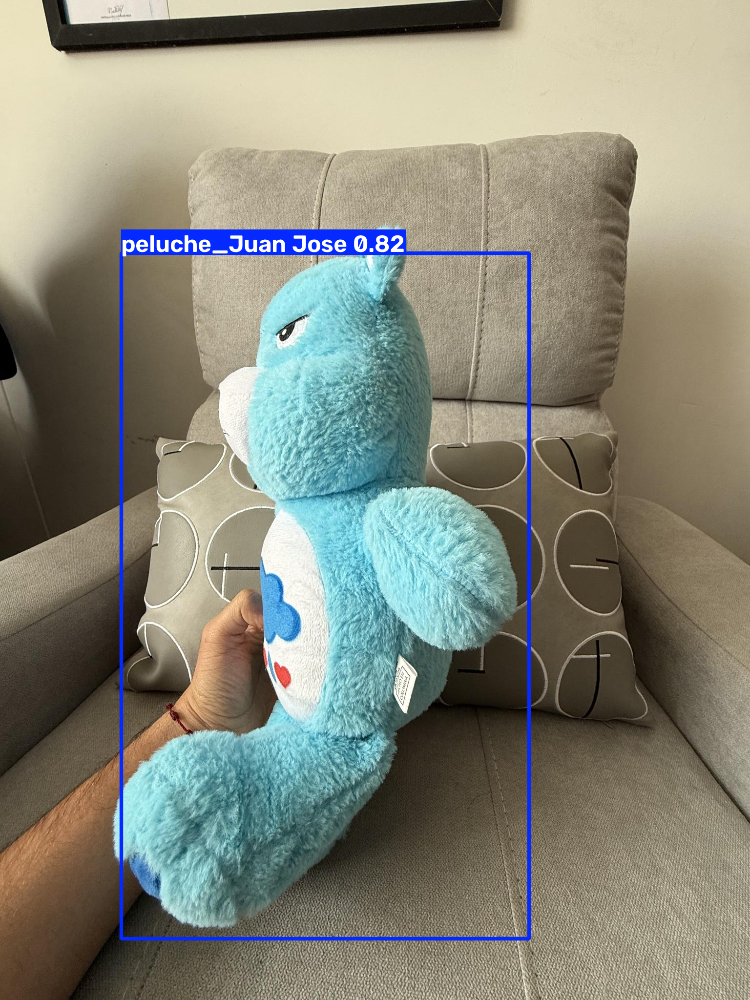

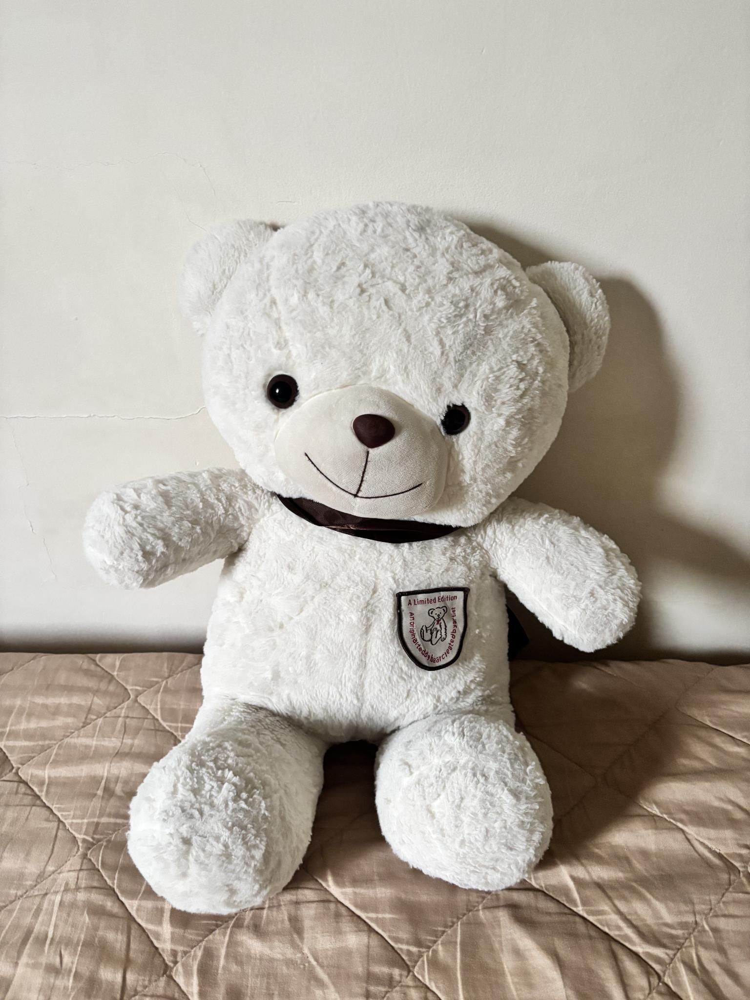

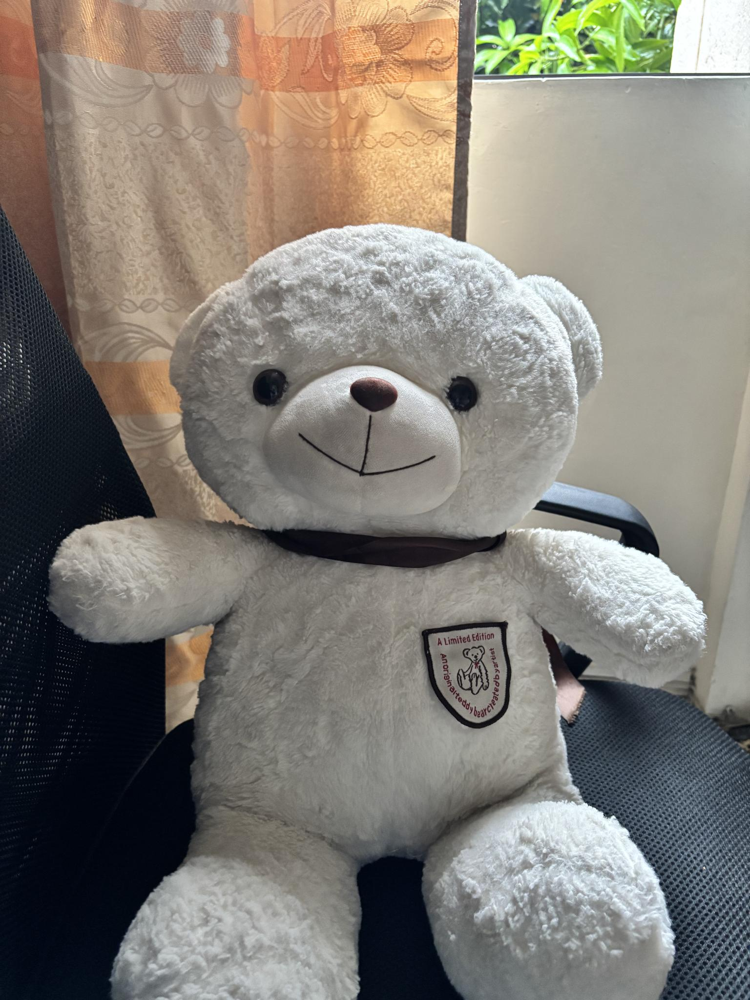

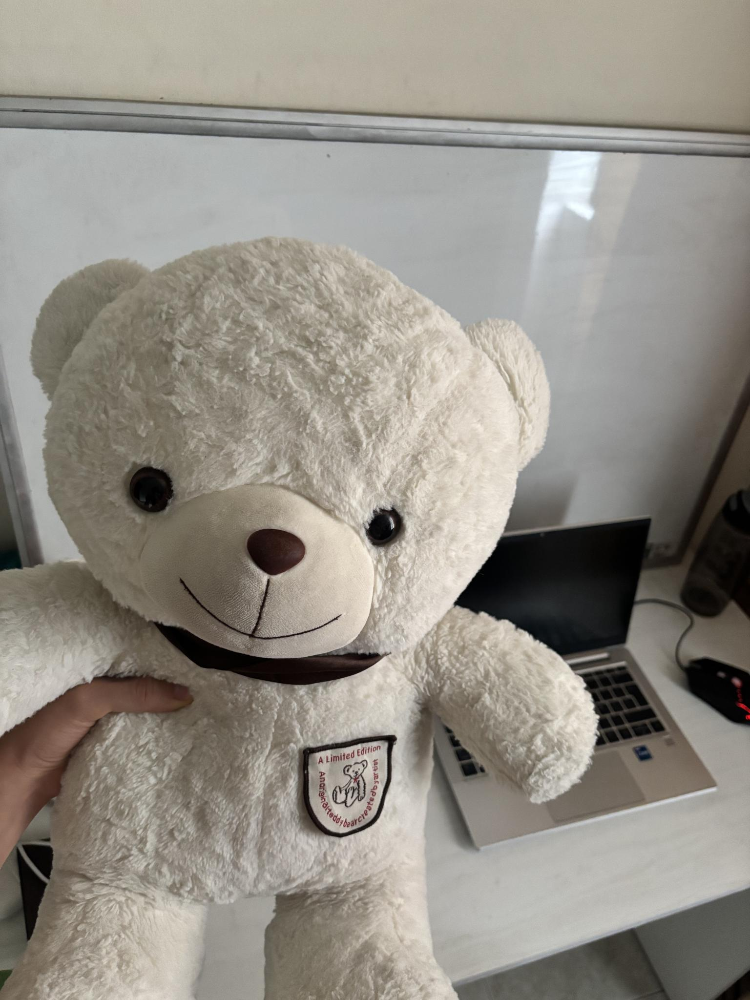

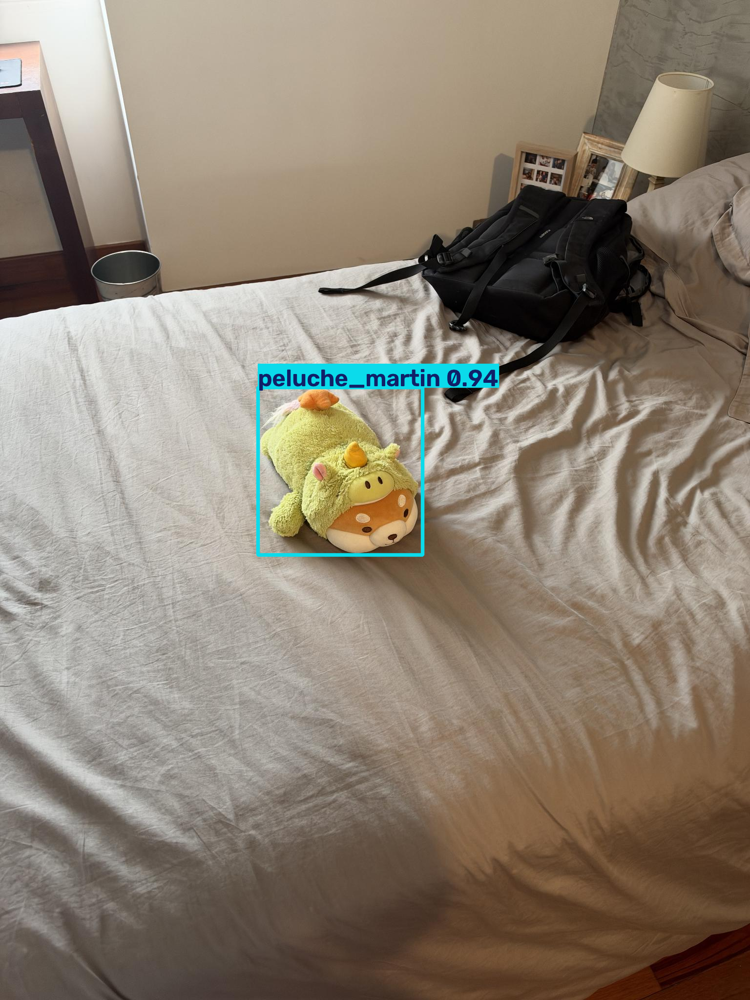

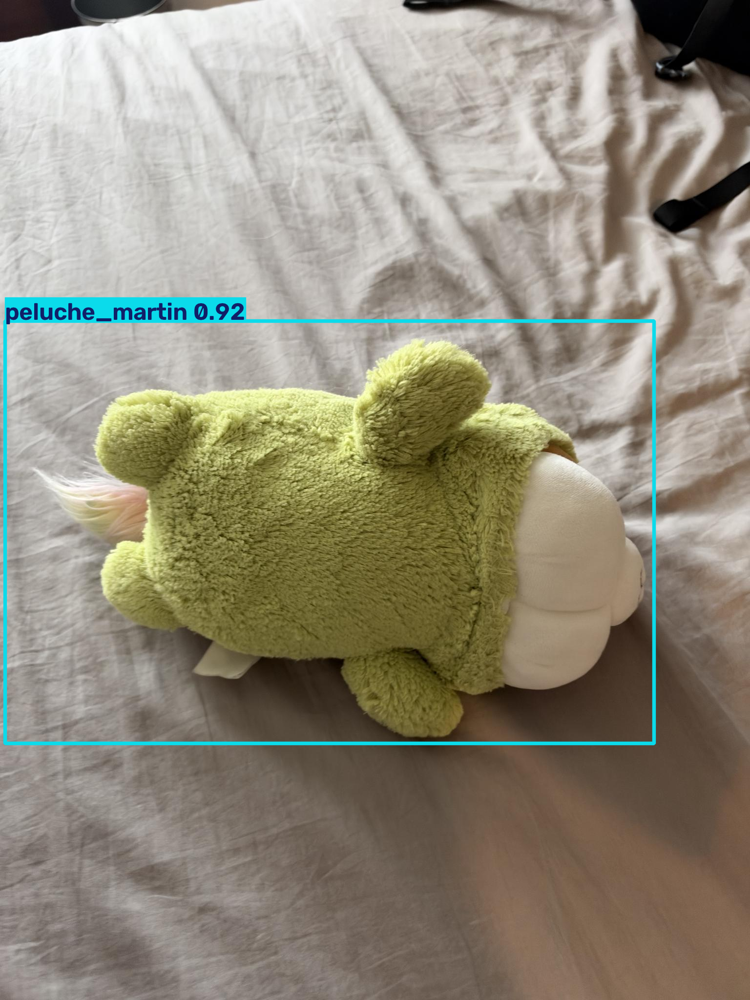

In [11]:
SOURCE = [str(p) for p in images_by_split["test"][:6]]
predictions = best_model.predict(
    source=SOURCE, conf=0.25, imgsz=IMAGE_SIZE, device=DEVICE,
    save=True, project=str(OUTPUT_DIR), name="predicciones",
)
for prediction in predictions:
    display(Image.fromarray(prediction.plot()[..., ::-1]))


## 10. Conservar el modelo

El archivo que necesitas para usar tu detector es `weights/best.pt` dentro de la carpeta de esta ejecución. Puede cargarse en otra sesión con `YOLO("ruta/al/best.pt")`. Conserva también el YAML, los parámetros y las métricas para comparar entrenamientos.

La exportación ONNX es opcional y se deja comentada: puede necesitar dependencias adicionales y su compatibilidad debe comprobarse en el equipo donde usarás el modelo.


In [12]:
print("Guarda este archivo:", BEST_WEIGHTS)
# Para cargarlo en otra sesión:
# detector = YOLO("ruta/al/best.pt")
# detector.predict(source="foto_nueva.jpg", save=True)

# Exportación opcional, cuando sepas cómo desplegarás el detector:
# best_model.export(format="onnx")


Guarda este archivo: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/nano/weights/best.pt
